In [193]:
import numpy as np
import matplotlib.pyplot as plt

### **METODE RELAKSASI / SOR**

In [194]:
def SOR(A, b, omega, epsilon=0.1, max_iter=100):
    n = len(A)
    x = [0.0] * n  # Tebakan awal 0
    history = [x.copy()]
    iterasi = 1

    while iterasi <= max_iter:
        x_new = x.copy()
        
        for i in range(n):
            jumlah = 0
            for j in range(n):
                if i != j:
                    # menggunakan x_new[j] yang selalu ter-update
                    jumlah += A[i][j] * x_new[j]
            
            # Menghitung nilai x baru
            x_gs = (b[i] - jumlah) / A[i][i]
            x_new[i] = (1 - omega) * x[i] + omega * x_gs

        history.append(x_new.copy())
        
        # Mengecek konvergensi (jika selisih dengan iterasi sebelumnya lebih kecil dari epsilon)
        err = max(abs(x_new[i] - x[i]) for i in range(n))
        if err < epsilon:
            print(f"Sistem konvergen pada iterasi ke-{iterasi}")
            return x_new, history
        
        # Update nilai x untuk iterasi selanjutnya
        x = x_new

        iterasi+=1

    print("MENCAPAI BATAS ITERASI --> 100")
    return x, history

### **METODE CONJUGASI GRADIEN**

In [195]:
def bicgstab(A, b, epsilon=0.1, max_iter=100):
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    
    x = np.zeros(n)           # Tebakan awal x0
    history = [x.copy()]      # Simpan riwayat untuk grafik
    
    r = b - A @ x             # Residual awal
    r_hat = r.copy()          # r_topi (vektor bayangan acak, biasanya disamakan dengan r awal)
    
    # Inisialisasi variabel internal BiCGSTAB
    rho_prev = 1.0
    alpha = 1.0
    omega = 1.0
    v = np.zeros(n)
    p = np.zeros(n)

    for iterasi in range(max_iter):
        x_old = x.copy()
        
        rho = np.dot(r_hat, r)
        
        # Mencegah pembagian dengan nol jika r_hat tegak lurus dengan r
        if rho == 0: 
            print("Peringatan: Metode gagal (rho = 0).")
            break
            
        beta = (rho / rho_prev) * (alpha / omega)
        p = r + beta * (p - omega * v)
        
        v = A @ p
        denom = np.dot(r_hat, v)
        
        if denom == 0:
            print("Peringatan: Metode gagal (pembagian dengan nol pada alpha).")
            break
            
        # 1. Tebakan langkah agresif (Mirip Conjugate Gradient)
        alpha = rho / denom
        s = r - alpha * v
        
        t = A @ s
        t_dot_t = np.dot(t, t)
        
        if t_dot_t == 0:
            omega = 0
        else:
            # 2. Fase Stabilisasi (Mencari langkah koreksi)
            omega = np.dot(t, s) / t_dot_t
            
        # Update tebakan x baru dengan menggabungkan langkah agresif & stabilisasi
        x = x + alpha * p + omega * s
        
        # Update residual
        r = s - omega * t
        
        history.append(x.copy())
        
        # ====================================================
        # KONDISI BERHENTI: Sesuai dengan gaya SOR kamu
        # Cek jika selisih x_baru dan x_lama < epsilon
        # ====================================================
        error_max = np.max(np.abs(x - x_old))
        if error_max < epsilon:
            print(f"BiCGSTAB konvergen pada iterasi ke-{iterasi + 1}")
            return x, history
            
        # Simpan rho untuk iterasi berikutnya
        rho_prev = rho

    print("Peringatan: Mencapai batas maksimum iterasi.")
    return x, history

### **OUTPUT + GRAFIK**

In [196]:
# variasi omega
def realisasi(kasus):
    A,b = kasus
    omega_list = [0.2, 0.6, 1.0, 1.4, 1.8]  # contoh: 5 nilai

    for o in omega_list:
        print(f'Omega: {o}')
        solusi, history = SOR(A, b, o)
        
        print("Solusi:")
        for i in range(len(A)):
            print(f"x{i+1}: {solusi[i]}")

        # Ambil nilai
        x1_values = [h[0] for h in history]
        x2_values = [h[1] for h in history]

        # Hitung error
        error_x = []
        error_y = []

        for i in range(1, len(history)):
            error_x.append(abs(history[i][0] - history[i-1][0]))
            error_y.append(abs(history[i][1] - history[i-1][1]))

        # =========================
        # VISUALISASI
        # =========================
        fig, axs = plt.subplots(2, 2, figsize=(10, 8))

        # Judul
        fig.suptitle(f"Omega : {o}", fontsize=16)

        iterasi_x = range(1, len(x1_values)+1)
        iterasi_error = range(1, len(error_x)+1)

        # Grafik x
        axs[0,0].plot(iterasi_x, x1_values)
        axs[0,0].set_title("Nilai x per Iterasi")
        axs[0,0].set_xlabel("Iterasi")
        axs[0,0].set_ylabel("x")
        axs[0,0].grid()

        # Grafik y
        axs[0,1].plot(iterasi_x, x2_values)
        axs[0,1].set_title("Nilai y per Iterasi")
        axs[0,1].set_xlabel("Iterasi")
        axs[0,1].set_ylabel("y")
        axs[0,1].grid()

        # Error x
        axs[1,0].semilogy(iterasi_error, error_x)
        axs[1,0].set_title("Error x")
        axs[1,0].set_xlabel("Iterasi")
        axs[1,0].set_ylabel("Error")
        axs[1,0].grid()

        # Error y
        axs[1,1].semilogy(iterasi_error, error_y)
        axs[1,1].set_title("Error y")
        axs[1,1].set_xlabel("Iterasi")
        axs[1,1].set_ylabel("Error")
        axs[1,1].grid()

        # Biar ga ketiban judul atas
        plt.tight_layout(rect=[0, 0, 1, 0.95])

        plt.show()

In [197]:
import matplotlib.pyplot as plt

def realisasi_perbandingan(kasus):
    A, b = kasus
    n_vars = len(b) # Menghitung otomatis jumlah variabel dari panjang array 'b'
    omega_list = [0.2, 0.6, 1.0, 1.4, 1.8]

    # ========================================================
    # 1. Jalankan Conjugate Gradient (Sekali Saja di Awal)
    # ========================================================
    print("Metode: BiConjugate Gradient Stabilized")
    solusi_cg, history_cg = bicgstab(A, b)
    for i in range(n_vars):
        print(f"x{i+1}: {solusi_cg[i]}")
    print("="*30)

    # Ekstrak data CG secara dinamis menggunakan list comprehension
    vals_cg = [[h[i] for h in history_cg] for i in range(n_vars)]
    errs_cg = [[abs(history_cg[j][i] - history_cg[j-1][i]) for j in range(1, len(history_cg))] for i in range(n_vars)]
    
    iterasi_cg = range(1, len(history_cg) + 1)
    iterasi_err_cg = range(1, len(history_cg)) # Panjangnya len - 1

    # ========================================================
    # 2. Loop Menguji Setiap Omega untuk SOR
    # ========================================================
    for o in omega_list:
        print(f"\nMetode: SOR (Omega: {o})")
        solusi_sor, history_sor = SOR(A, b, o)
        
        print("Solusi:")
        for i in range(n_vars):
            print(f"x{i+1}: {solusi_sor[i]}")
        
        # Ekstrak data SOR secara dinamis
        vals_sor = [[h[i] for h in history_sor] for i in range(n_vars)]
        errs_sor = [[abs(history_sor[j][i] - history_sor[j-1][i]) for j in range(1, len(history_sor))] for i in range(n_vars)]
        
        iterasi_sor = range(1, len(history_sor) + 1)
        iterasi_err_sor = range(1, len(history_sor))

        # =========================
        # VISUALISASI DINAMIS
        # =========================
        # Membuat grid subplot: Baris = jumlah variabel, Kolom = 2
        # Tinggi gambar disesuaikan (4 inci per baris variabel) agar tidak berdesakan
        fig, axs = plt.subplots(n_vars, 2, figsize=(12, 4 * n_vars)) 
        
        # Penyesuaian dimensi array 'axs' jika kebetulan variabelnya cuma 1
        if n_vars == 1:
            axs = [axs] 

        fig.suptitle(f"Perbandingan Performa: SOR (Omega = {o}) vs BiConjugate Gradient Stabilized", fontsize=16)

        # Loop untuk menggambar grafik per variabel
        for i in range(n_vars):
            # --- Grafik Kolom Kiri: Nilai x ---
            axs[i,0].plot(iterasi_sor, vals_sor[i], label='SOR', color='blue', marker='o')
            axs[i,0].plot(iterasi_cg, vals_cg[i], label='BiCGS', color='orange', linestyle='--', marker='x')
            axs[i,0].set_title(f"Nilai x{i+1} per Iterasi")
            axs[i,0].set_xlabel("Iterasi")
            axs[i,0].set_ylabel(f"x{i+1}")
            axs[i,0].grid(True)
            axs[i,0].legend()

            # --- Grafik Kolom Kanan: Error x ---
            if errs_sor[i]:
                axs[i,1].semilogy(iterasi_err_sor, errs_sor[i], label='SOR', color='blue')
            if errs_cg[i]:
                axs[i,1].semilogy(iterasi_err_cg, errs_cg[i], label='BiCGS', color='orange', linestyle='--')
            axs[i,1].set_title(f"Error x{i+1}")
            axs[i,1].set_xlabel("Iterasi")
            axs[i,1].set_ylabel("Error")
            axs[i,1].grid(True)
            axs[i,1].legend()

        # Merapikan jarak antar subplot dan judul
        plt.tight_layout(rect=[0, 0, 1, 0.97])
        plt.show()

### **KASUS 1**

# 📌 Kasus Produksi Dua Mesin dalam Sistem Industri

Kasus ini memodelkan proses produksi pada sebuah pabrik yang menggunakan **dua mesin utama** untuk menghasilkan dua jenis produk secara paralel.

* **Mesin A**
* **Mesin B**

Kedua mesin memiliki kontribusi produksi yang berbeda pada masing-masing produk.

---

## 🔹 Karakteristik Produksi

### ⚙️ Produk 1

* Produksi didominasi oleh **Mesin A**
* Rasio kontribusi: **8 : 1** (A : B)
* Total produksi: **36 unit**

---

### 🏭 Produk 2

* Produksi didominasi oleh **Mesin B**
* Rasio kontribusi: **1 : 5** (A : B)
* Total produksi: **30 unit**

---

## 🔹 Pemodelan Sistem Persamaan Linear (SPL)

Misalkan:

* $x_1$ = kapasitas produksi **Mesin A**
* $x_2$ = kapasitas produksi **Mesin B**

Berdasarkan informasi yang diberikan, diperoleh sistem persamaan:

$$
\begin{cases}
8x_1 + x_2 = 36 \\
x_1 + 5x_2 = 30
\end{cases}
$$

---

## 🔹 Interpretasi Matriks

Sistem di atas dapat dituliskan dalam bentuk matriks sebagai berikut:

$$
\begin{bmatrix}
8 & 1 \\
1 & 5
\end{bmatrix}
\begin{bmatrix}
x_1 \\
x_2
\end{bmatrix}
=

\begin{bmatrix}
36 \\
30
\end{bmatrix}
$$

---

## 🔹 Representasi Matriks

$$
A =
\begin{bmatrix}
8 & 1 \\
1 & 5
\end{bmatrix}
\quad
b =
\begin{bmatrix}
36 \\
30
\end{bmatrix}
$$

---

## 🔹 Tujuan

Menentukan nilai:

* $x_1$ → kapasitas produksi Mesin A
* $x_2$ → kapasitas produksi Mesin B

agar sistem produksi memenuhi target kedua produk secara optimal.


Metode: BiConjugate Gradient Stabilized
BiCGSTAB konvergen pada iterasi ke-3
x1: 3.8461538461538463
x2: 5.230769230769231

Metode: SOR (Omega: 0.2)
Sistem konvergen pada iterasi ke-11
Solusi:
x1: 3.6511446402237437
x2: 4.892905077681133


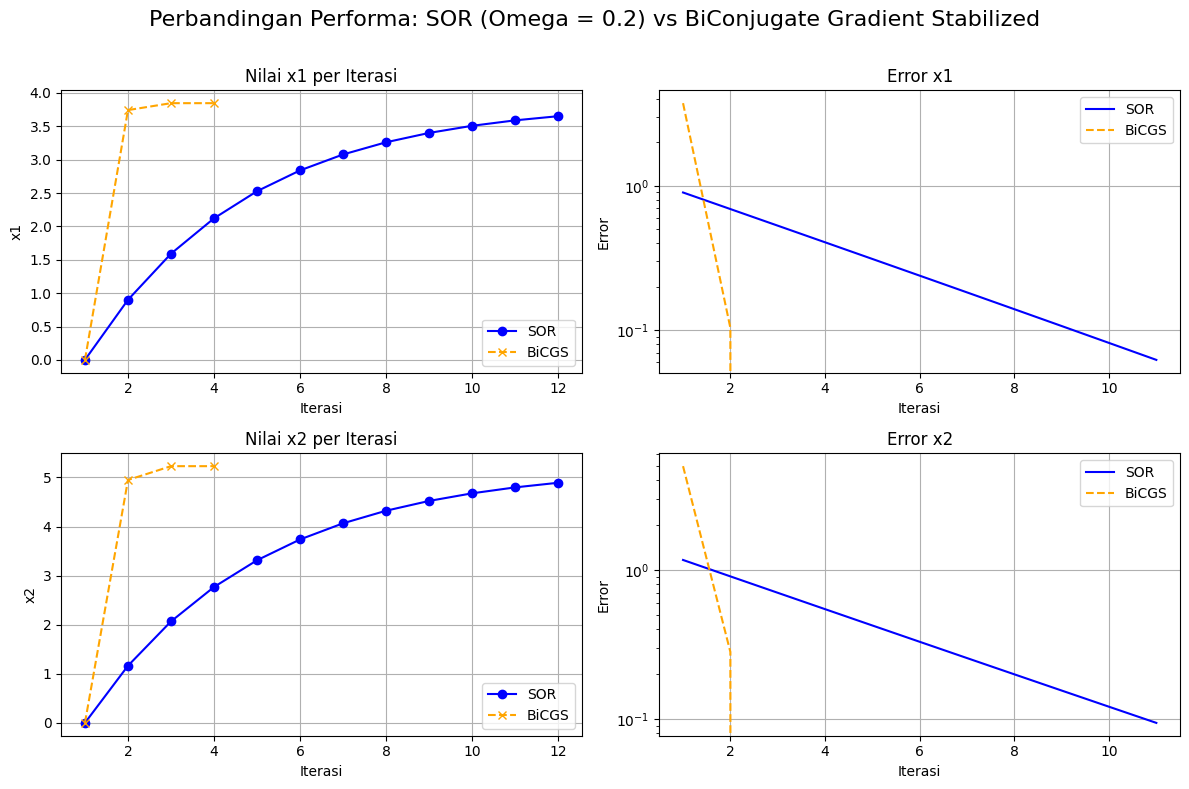


Metode: SOR (Omega: 0.6)
Sistem konvergen pada iterasi ke-5
Solusi:
x1: 3.8524479224247004
x2: 5.183970552750636


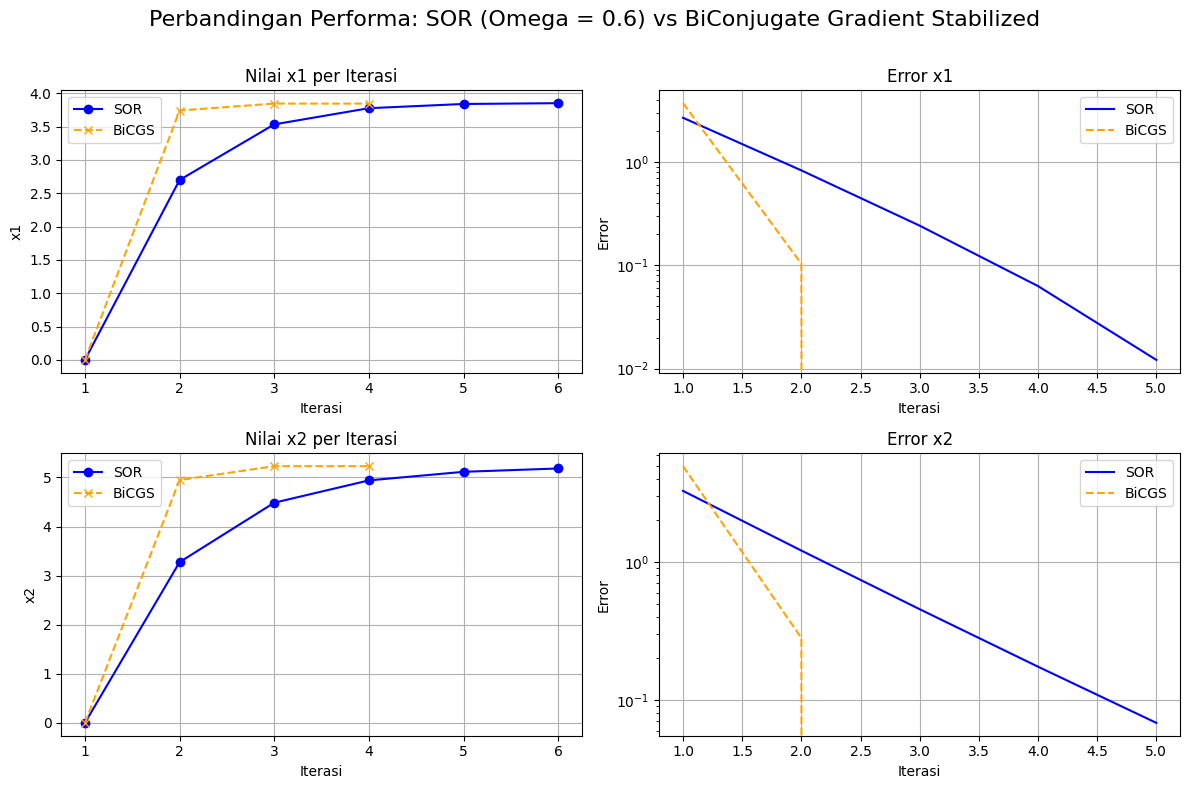


Metode: SOR (Omega: 1.0)
Sistem konvergen pada iterasi ke-3
Solusi:
x1: 3.8465625
x2: 5.2306875


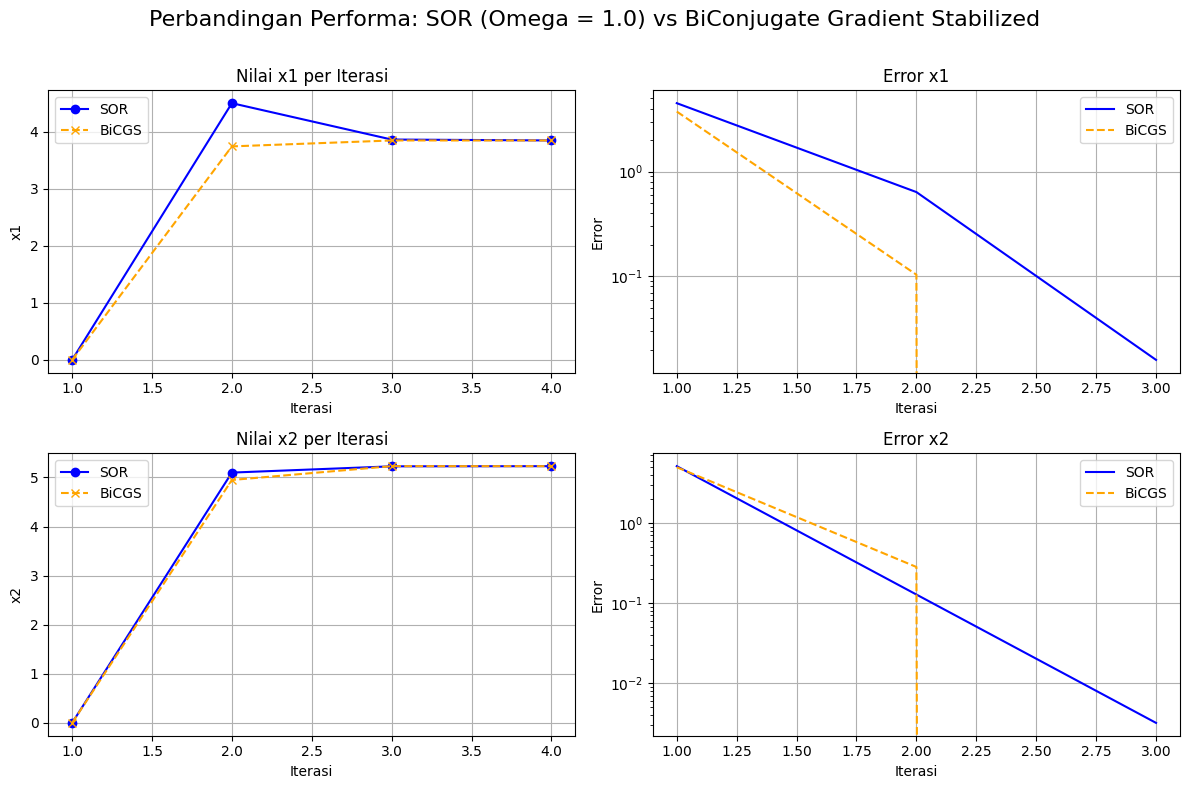


Metode: SOR (Omega: 1.4)
Sistem konvergen pada iterasi ke-6
Solusi:
x1: 3.828523087278219
x2: 5.256030935106644


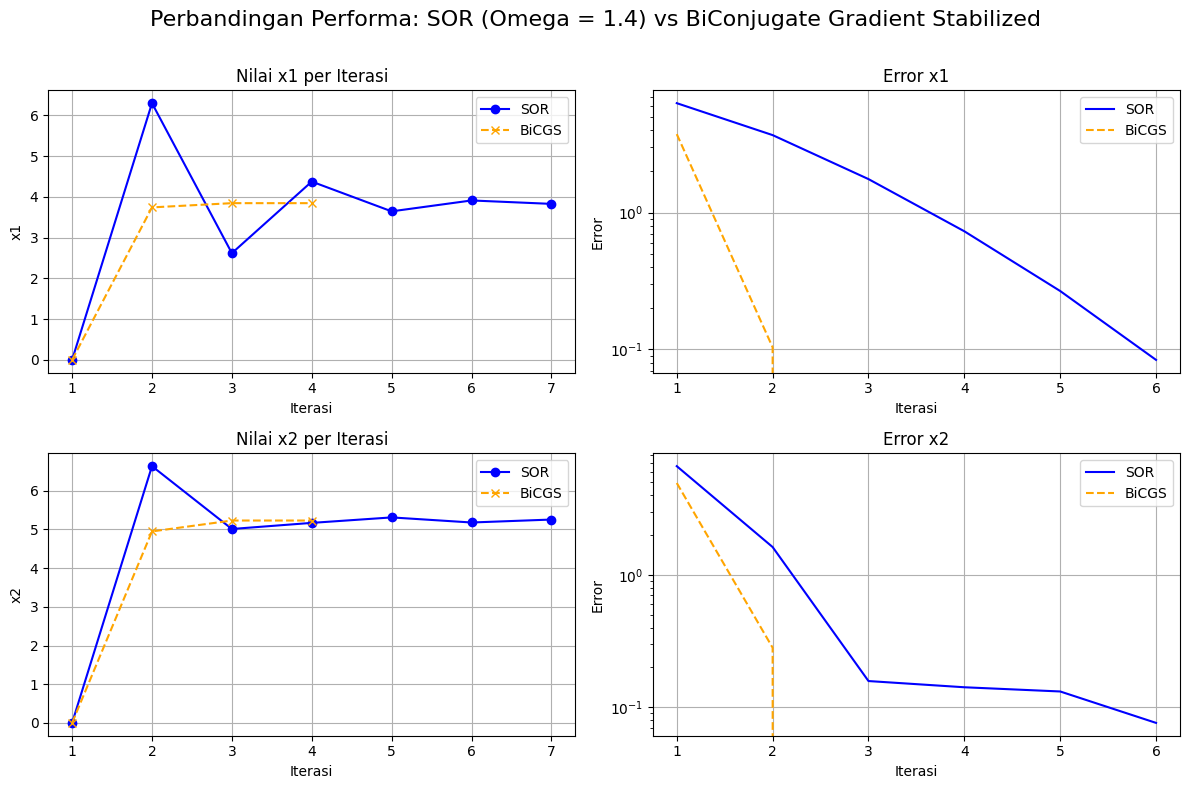


Metode: SOR (Omega: 1.8)
Sistem konvergen pada iterasi ke-22
Solusi:
x1: 3.7987451685534057
x2: 5.228775356444074


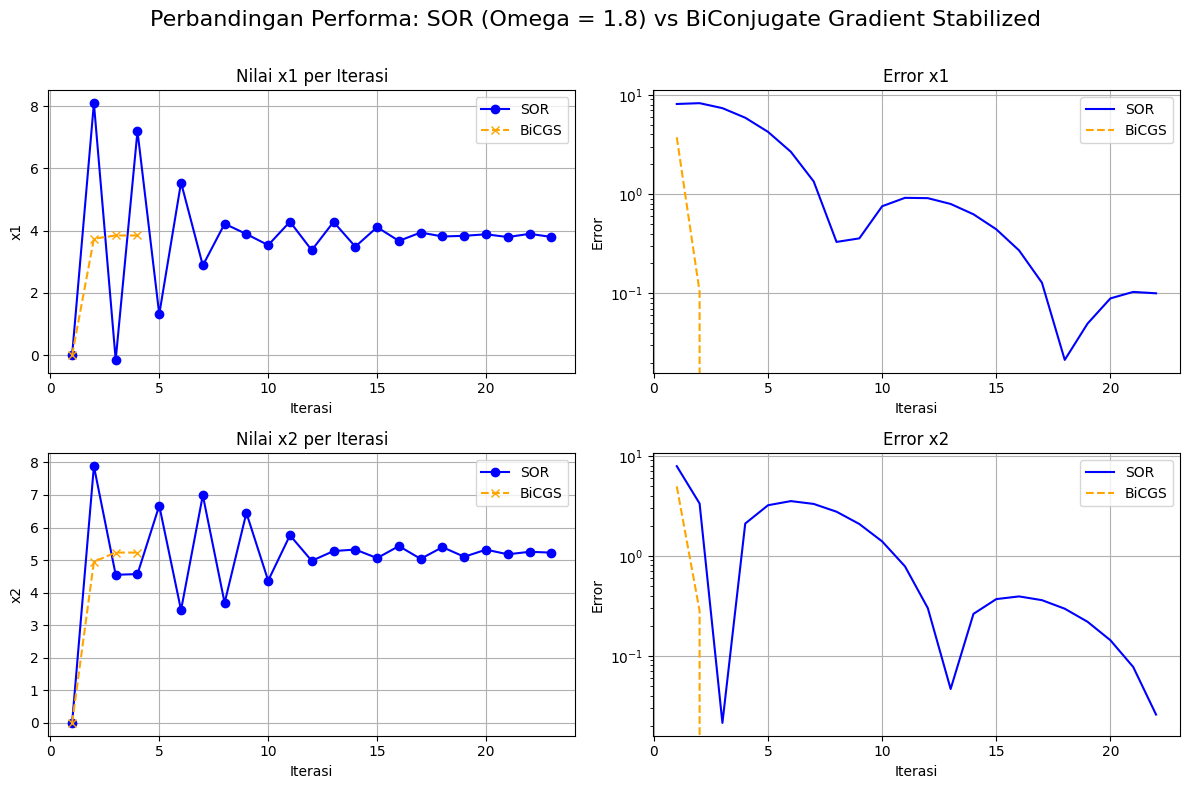

In [198]:
#Matriks A
A = np.array([
    [8, 1],
    [1, 5]
], dtype=float)

#Matriks b
b = np.array([36, 30], dtype=float)

kasus1 = (A,b)

realisasi_perbandingan(kasus1)

# 📌 Kasus Alokasi Cache Memory pada Prosesor Modern

Kasus ini memodelkan permasalahan **alokasi cache memory** pada prosesor modern yang terdiri dari tiga level cache:

- **L1 Cache**
- **L2 Cache**
- **L3 Cache**

Ketiga cache ini harus dialokasikan secara optimal untuk melayani tiga jenis proses yang berjalan bersamaan.

---

## 🔹 Karakteristik Proses

### 🧠 Process A (CPU-intensive)
- Dominan mengakses cache **L1**
- Sedikit akses ke L2 dan L3

### 💾 Process B (Memory-intensive)
- Dominan mengakses cache **L2**
- Sedikit akses ke L1 dan L3

### 🔌 Process C (I/O-intensive)
- Dominan mengakses cache **L3**
- Sedikit akses ke L1 dan L2

---

## 🔹 Pemodelan Sistem Persamaan Linear (SPL)

Misalkan:

- $x$ = kapasitas cache **L1** (MB)
- $y$ = kapasitas cache **L2** (MB)
- $z$ = kapasitas cache **L3** (MB)

Maka diperoleh sistem persamaan:

$$
\begin{cases}
9x + 2y + z = 55 \\
x + 7y + 2z = 41 \\
2x + y + 8z = 37
\end{cases}
$$

---

## 🔹 Interpretasi Matriks

Sistem di atas dapat ditulis dalam bentuk matriks:

$$
\begin{bmatrix}
9 & 2 & 1 \\
1 & 7 & 2 \\
2 & 1 & 8
\end{bmatrix}
\begin{bmatrix}
x \\
y \\
z
\end{bmatrix}
=
\begin{bmatrix}
55 \\
41 \\
37
\end{bmatrix}
$$

---

## 🔹 Representasi Matriks

$$
A =
\begin{bmatrix}
9 & 2 & 1 \\
1 & 7 & 2 \\
2 & 1 & 8
\end{bmatrix}
\quad
b =
\begin{bmatrix}
55 \\
41 \\
37
\end{bmatrix}
$$

---

## 🔹 Tujuan

Menentukan nilai optimal:

- $x$ → alokasi cache L1  
- $y$ → alokasi cache L2  
- $z$ → alokasi cache L3  

agar performa sistem prosesor menjadi optimal untuk ketiga jenis proses.


In [199]:
#Kasus 2
A = np.array([
    [3, 1, 0],
    [1, 4, 1],
    [4, 4, 9]
], dtype= float)

b = np.array([
    70,
    100,
    500
], dtype= float)

kasus2 = (A, b)

Metode: BiConjugate Gradient Stabilized
BiCGSTAB konvergen pada iterasi ke-4
x1: 20.219780219780215
x2: 9.340659340659338
x3: 42.4175824175824

Metode: SOR (Omega: 0.2)
Sistem konvergen pada iterasi ke-21
Solusi:
x1: 19.630879705149784
x2: 9.984141709486746
x3: 42.08696891724243


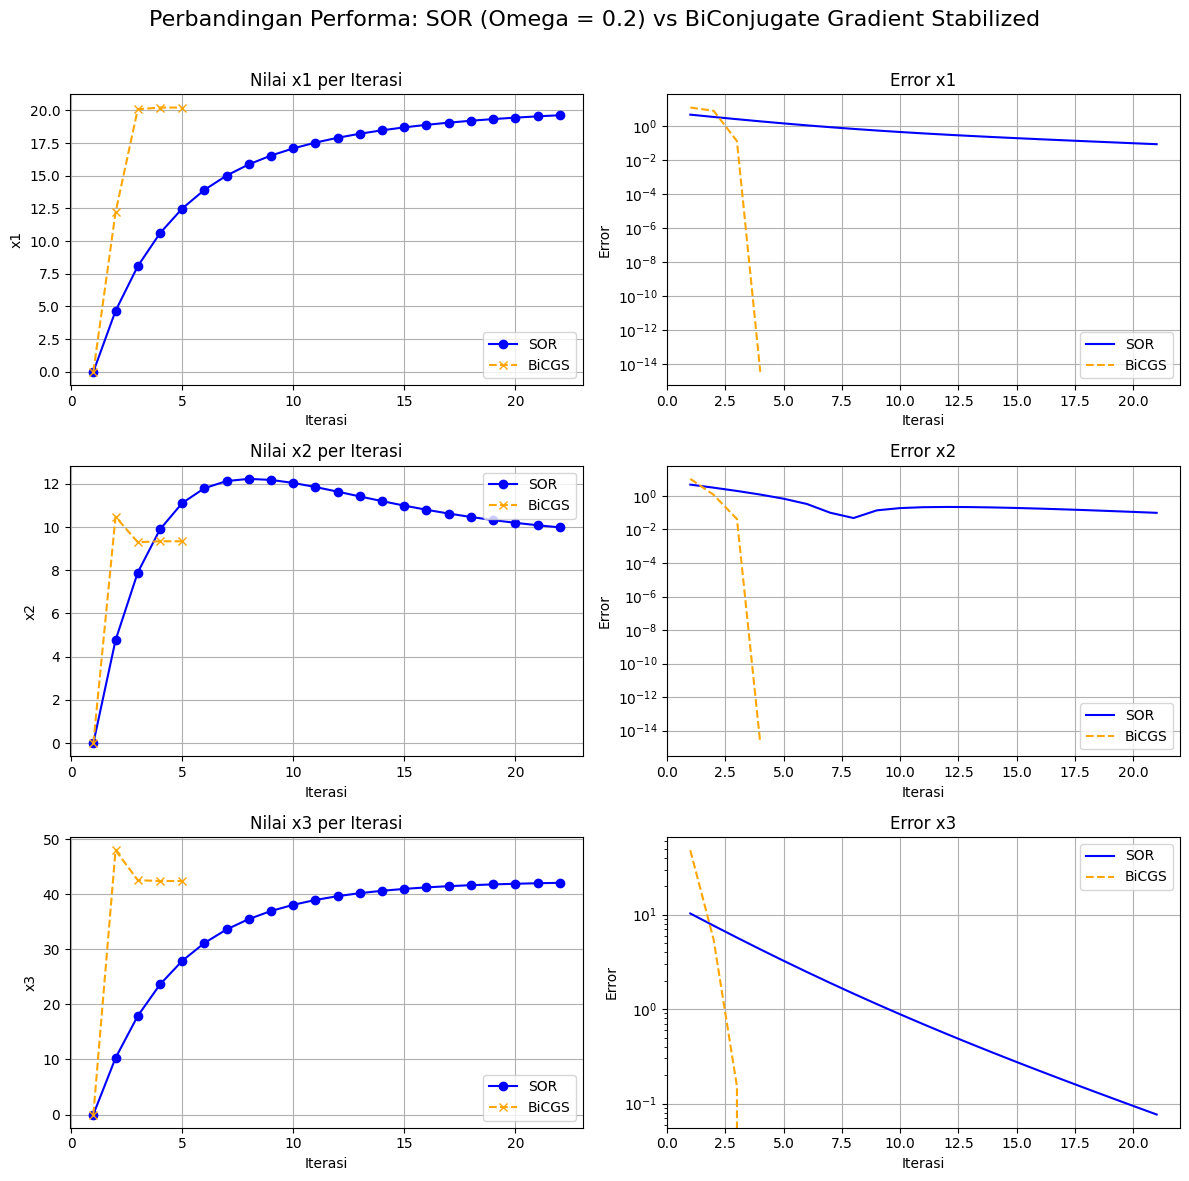


Metode: SOR (Omega: 0.6)
Sistem konvergen pada iterasi ke-9
Solusi:
x1: 20.09885510508905
x2: 9.43341782449158
x3: 42.41589579956716


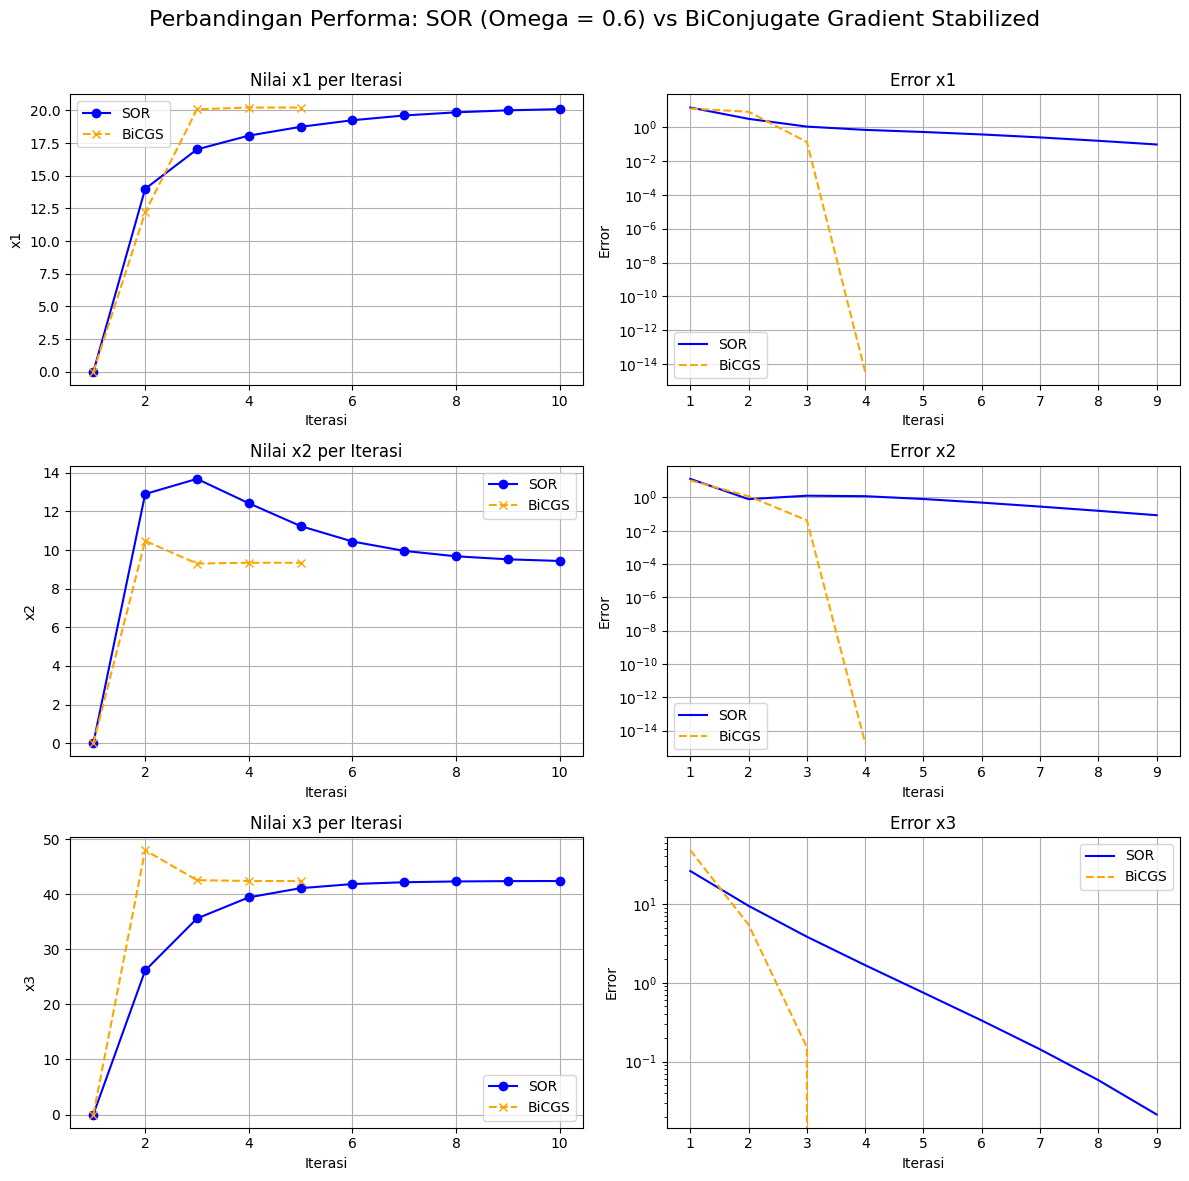


Metode: SOR (Omega: 1.0)
Sistem konvergen pada iterasi ke-5
Solusi:
x1: 20.242787637174214
x2: 9.324466127972109
x3: 42.41455388215719


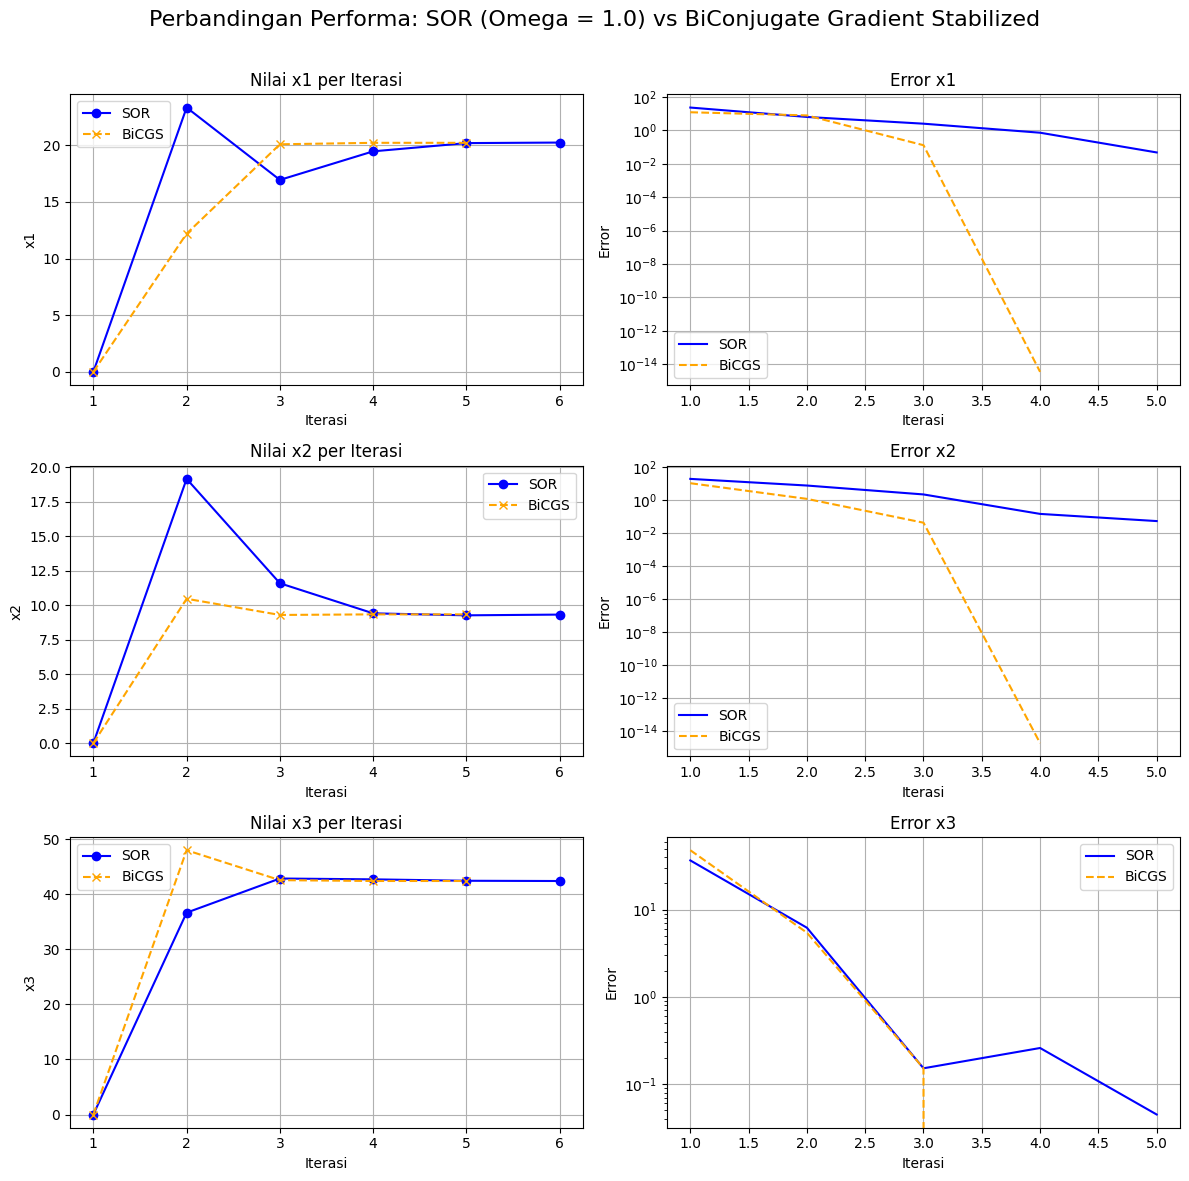


Metode: SOR (Omega: 1.4)
Sistem konvergen pada iterasi ke-12
Solusi:
x1: 20.245469671441683
x2: 9.336135023279857
x3: 42.394007205583414


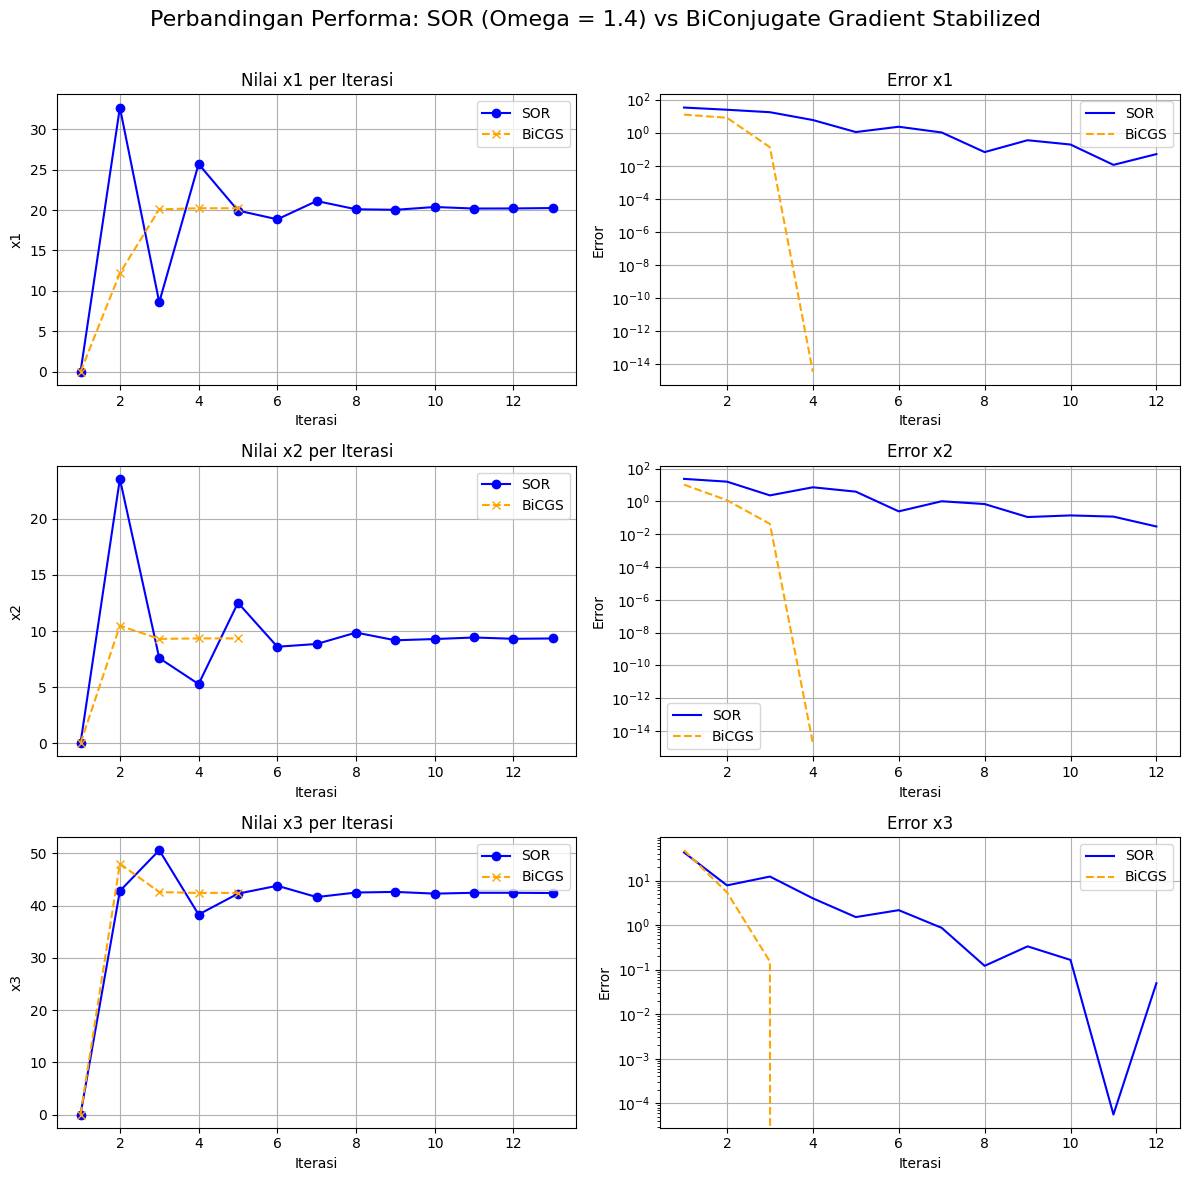


Metode: SOR (Omega: 1.8)
MENCAPAI BATAS ITERASI --> 100
Solusi:
x1: 18.160240813727484
x2: 0.30407682032761585
x3: 47.16763997220772


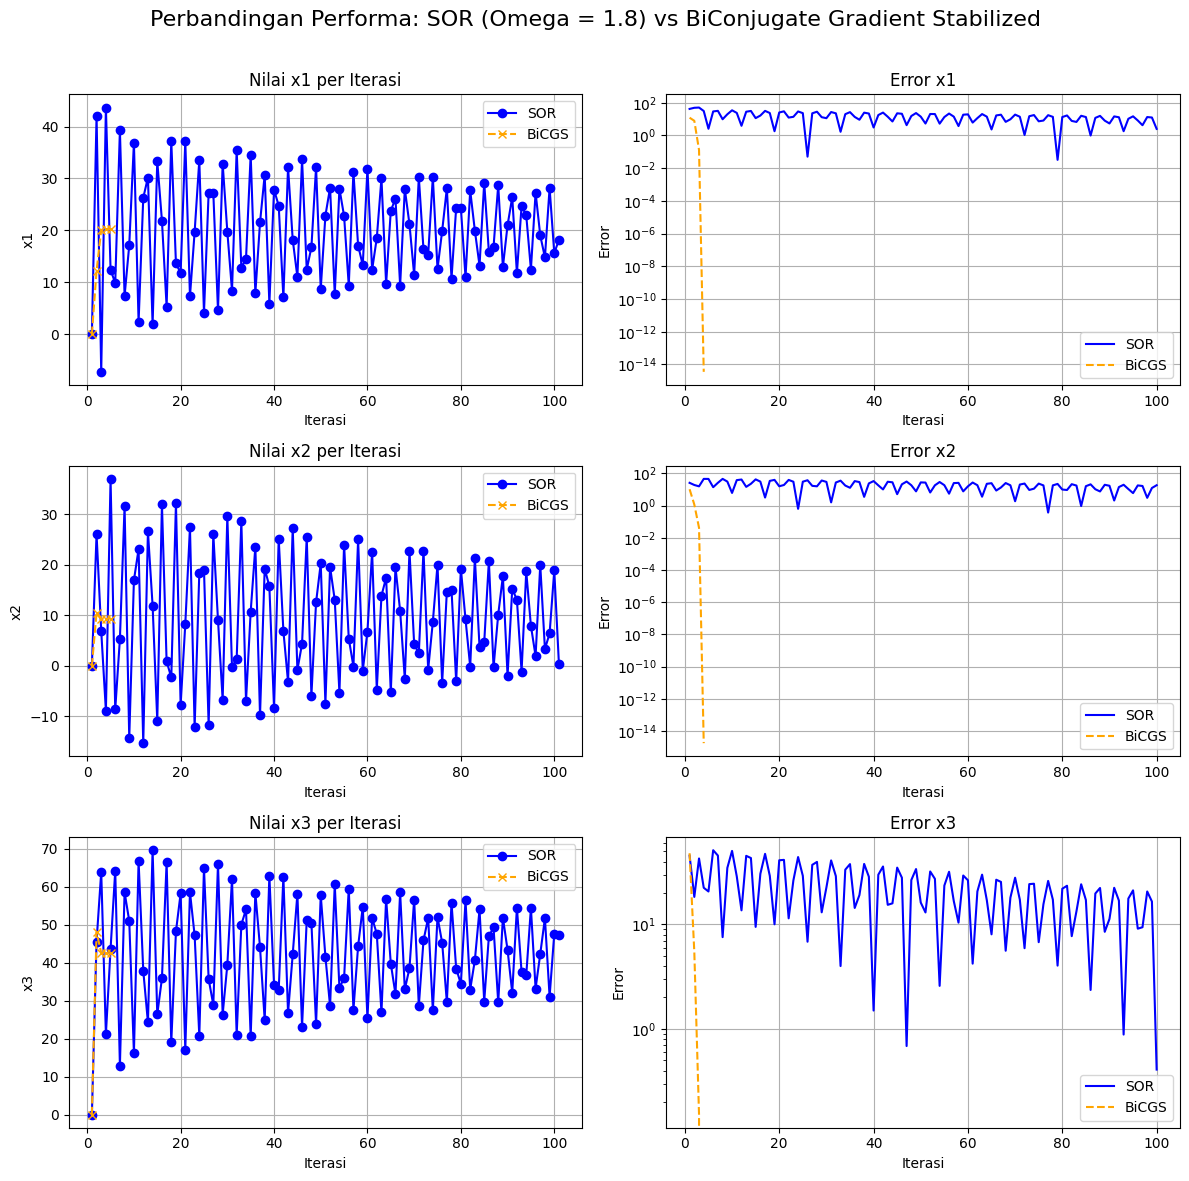

In [200]:
realisasi_perbandingan(kasus2)